# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

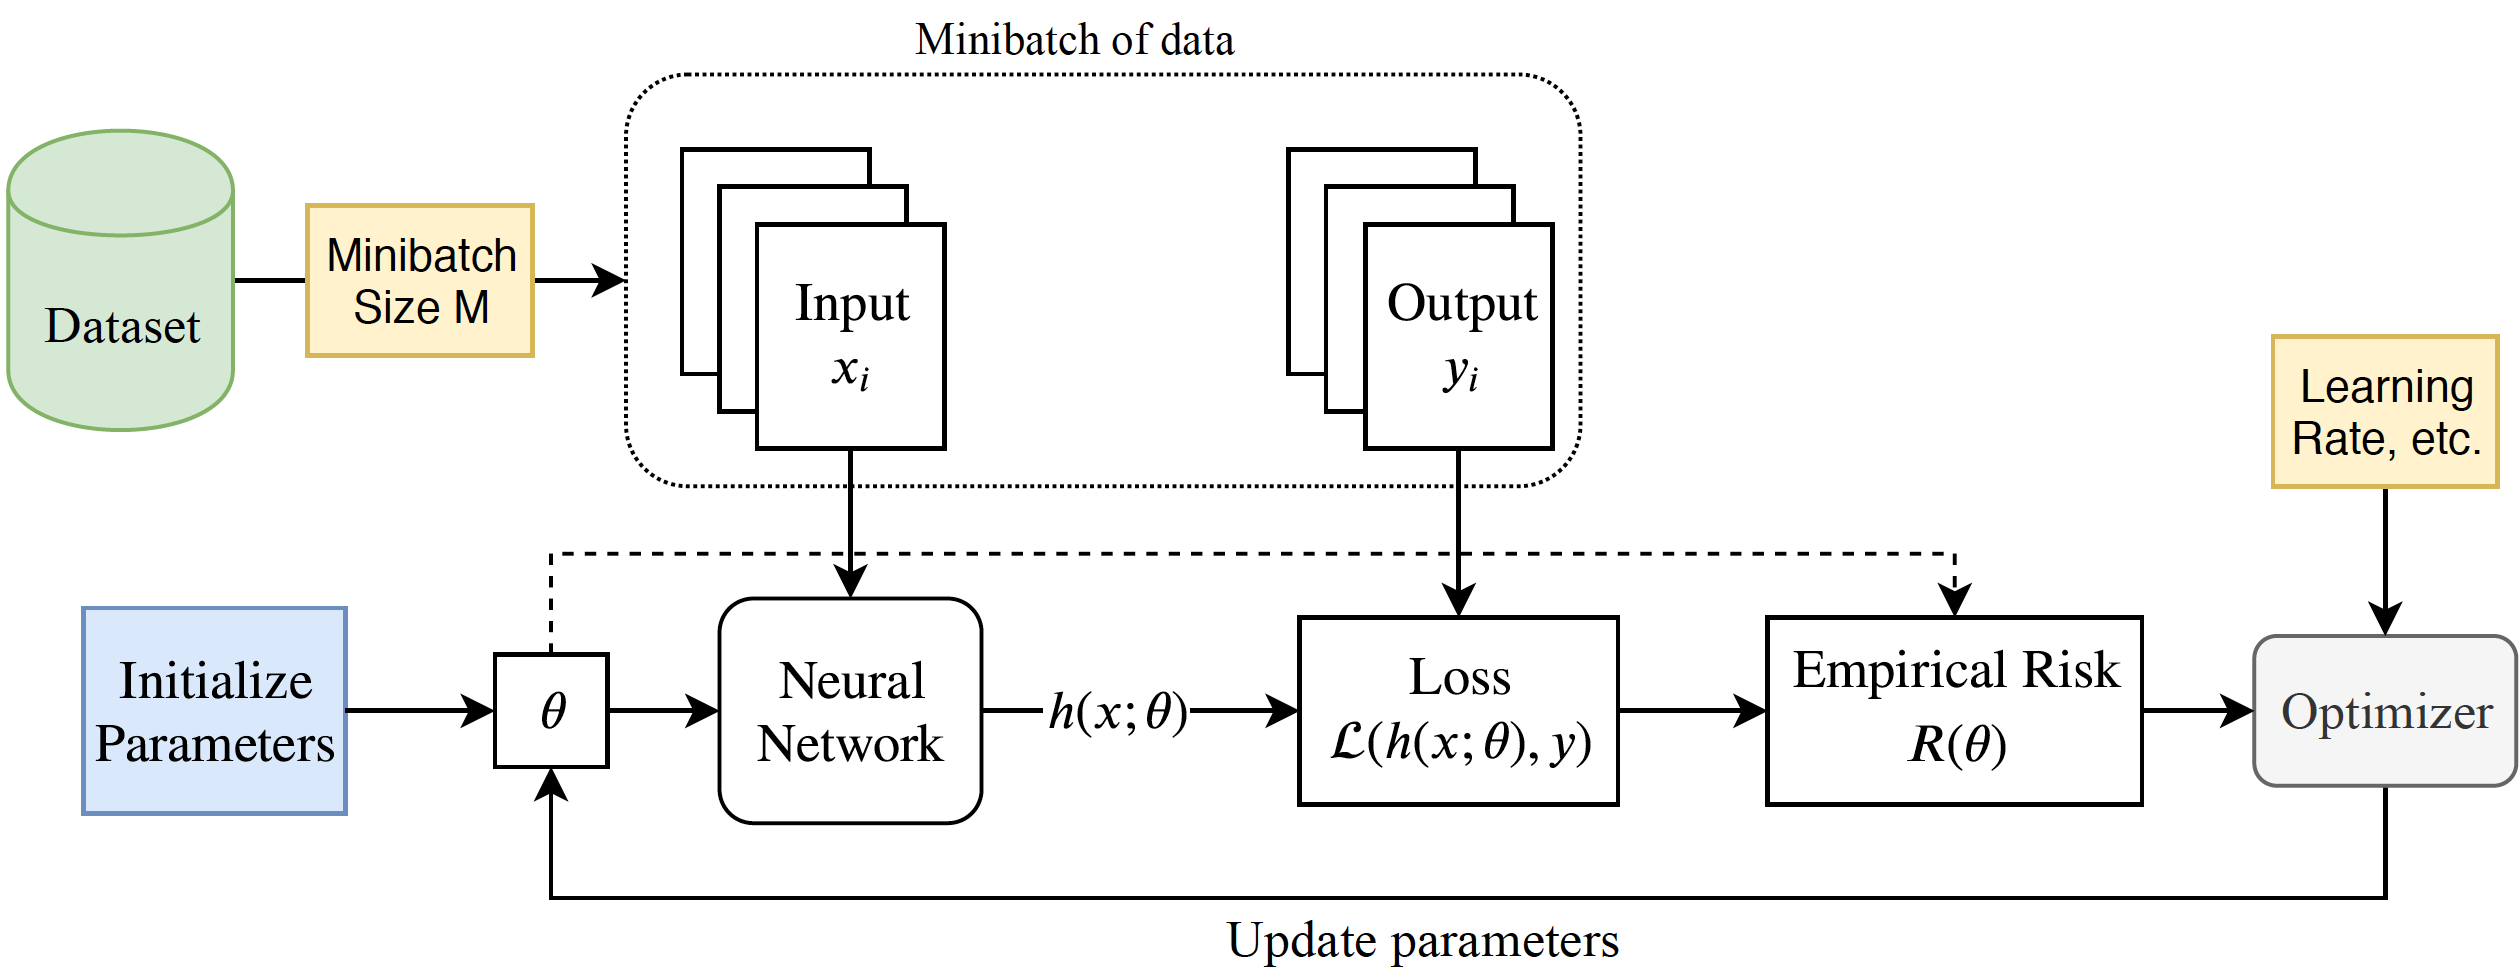

## 0 · Setup

In [ ]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


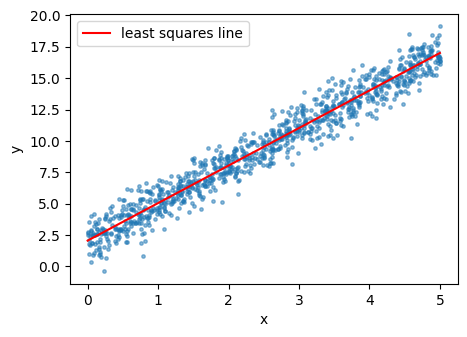

In [ ]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [ ]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [ ]:
hist_sgd = train_toy(batch_size=1)

epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 8.08 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [ ]:
hist_mb = train_toy(batch_size=32)

epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.26 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [ ]:
hist_mom = train_toy(batch_size=32, momentum=0.9)

epoch  5 | J = 0.9845 | w = 2.942, b = 2.004
epoch 10 | J = 1.1423 | w = 3.120, b = 2.128
epoch 15 | J = 0.9601 | w = 3.024, b = 2.063
epoch 20 | J = 0.9495 | w = 2.997, b = 2.051
updates: 640 | training time: 0.28 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

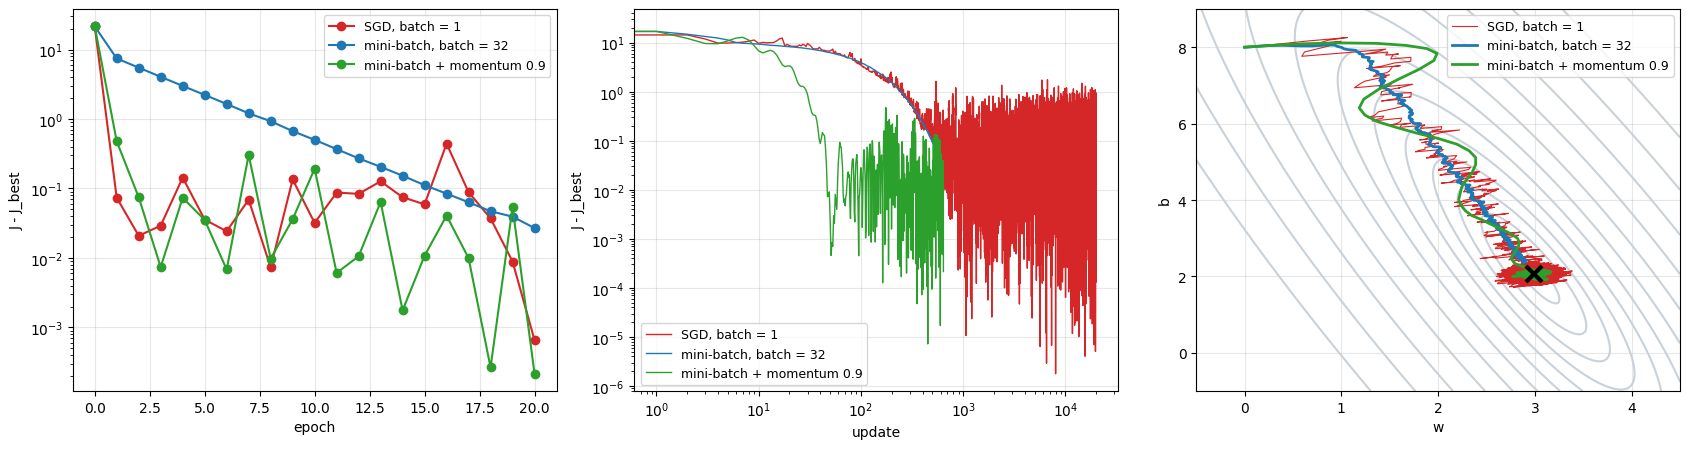

SGD, batch = 1               updates:  20000 | time: 8.08 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.26 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    640 | time: 0.28 s | final J - J_best: 0.0002


In [ ]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.52MB/s]


train (54000, 784) | val (6000, 784) | test (10000, 784)


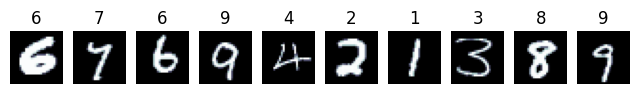

In [ ]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [ ]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.5883 | val loss 0.3269 | val acc 90.13% | 0.9 s
epoch  2 | lr 1.00e-03 | train loss 0.2570 | val loss 0.2603 | val acc 92.10% | 1.3 s
epoch  3 | lr 1.00e-03 | train loss 0.1828 | val loss 0.2301 | val acc 93.05% | 1.8 s


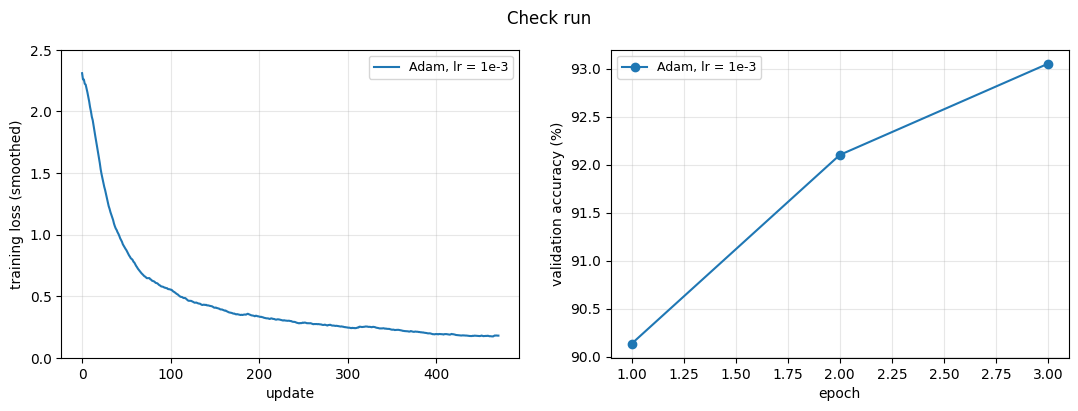

In [ ]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000), epochs=3)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

epoch  1 | lr 1.00e+00 | train loss 2.5133 | val loss 1.5974 | val acc 41.28% | 0.5 s
epoch  2 | lr 1.00e+00 | train loss 1.9113 | val loss 1.9293 | val acc 26.33% | 0.8 s
epoch  3 | lr 1.00e+00 | train loss 1.8403 | val loss 1.8354 | val acc 28.73% | 1.2 s
epoch  4 | lr 1.00e+00 | train loss 1.8480 | val loss 2.1606 | val acc 18.00% | 1.5 s
epoch  5 | lr 1.00e+00 | train loss 2.0679 | val loss 2.0615 | val acc 18.92% | 1.9 s
epoch  1 | lr 3.00e-01 | train loss 0.6940 | val loss 0.3263 | val acc 90.67% | 0.4 s
epoch  2 | lr 3.00e-01 | train loss 0.2314 | val loss 0.3524 | val acc 89.68% | 0.8 s
epoch  3 | lr 3.00e-01 | train loss 0.1474 | val loss 0.2704 | val acc 92.18% | 1.1 s
epoch  4 | lr 3.00e-01 | train loss 0.1072 | val loss 1.6728 | val acc 77.85% | 1.4 s
epoch  5 | lr 3.00e-01 | train loss 0.1064 | val loss 0.2282 | val acc 93.27% | 1.7 s
epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.3 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 

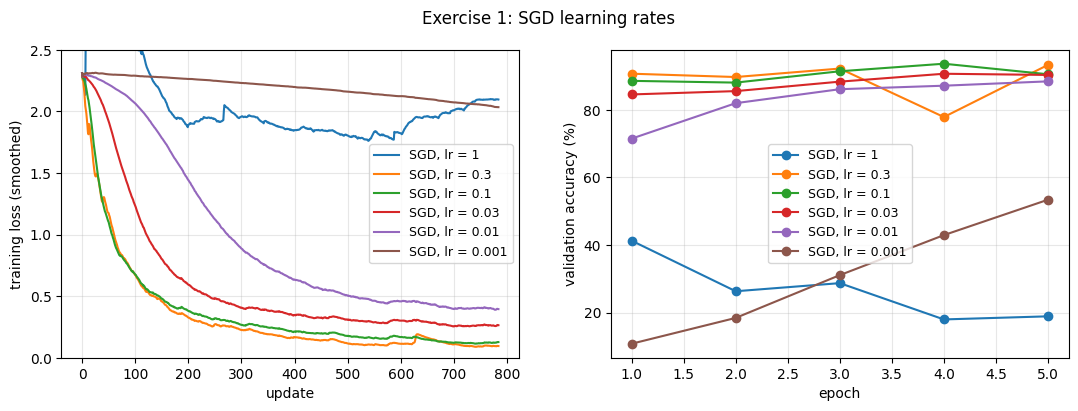

In [ ]:
import torch.optim as optim

lrs = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
results = {}

for lr in lrs:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)   # no momentum
    results[f"SGD, lr = {lr}"] = fit(
        model, optimizer,
        make_loader(batch_size=64, n_train=10_000),
        epochs=5,
    )

plot_history(results, "Exercise 1: SGD learning rates")   # one figure, one curve per lr

In [ ]:
for name, h in results.items():
    accs = [x for x in h["val_acc"] if not math.isnan(x)]   # skip NaNs from diverged runs
    best = max(accs) if accs else float("nan")
    print(f"{name:18s} best val acc = {best:.4f}")

SGD, lr = 1        best val acc = 41.2833
SGD, lr = 0.3      best val acc = 93.2667
SGD, lr = 0.1      best val acc = 93.6167
SGD, lr = 0.03     best val acc = 90.6500
SGD, lr = 0.01     best val acc = 88.4000
SGD, lr = 0.001    best val acc = 53.4000


By using optim.SGD with Learning rate 0.1 has the best training accuraccy with 93.6167

epoch  1 | lr 1.00e+00 | train loss 2.5133 | val loss 1.5974 | val acc 41.28% | 0.3 s
epoch  2 | lr 1.00e+00 | train loss 1.9113 | val loss 1.9293 | val acc 26.33% | 0.6 s
epoch  3 | lr 1.00e+00 | train loss 1.8403 | val loss 1.8354 | val acc 28.73% | 0.9 s
epoch  4 | lr 1.00e+00 | train loss 1.8480 | val loss 2.1606 | val acc 18.00% | 1.2 s
epoch  5 | lr 1.00e+00 | train loss 2.0679 | val loss 2.0615 | val acc 18.92% | 1.5 s


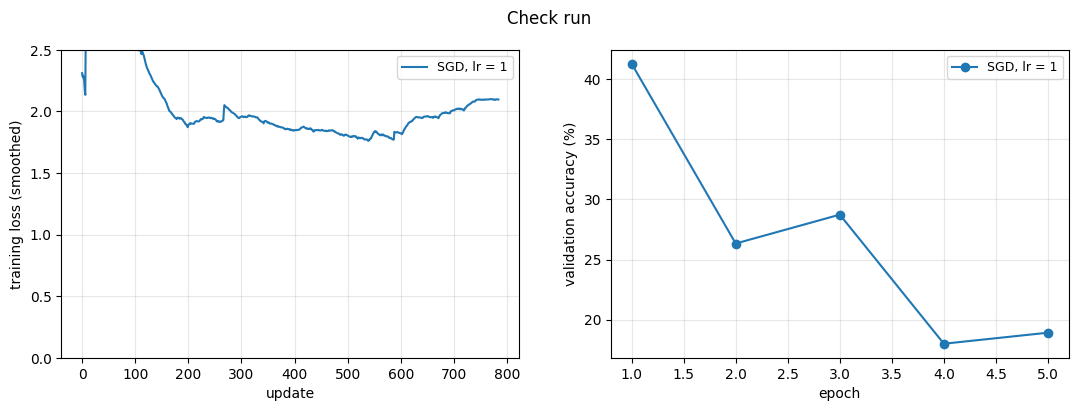

epoch  1 | lr 3.00e-01 | train loss 0.6940 | val loss 0.3263 | val acc 90.67% | 0.3 s
epoch  2 | lr 3.00e-01 | train loss 0.2314 | val loss 0.3524 | val acc 89.68% | 0.6 s
epoch  3 | lr 3.00e-01 | train loss 0.1474 | val loss 0.2704 | val acc 92.18% | 0.9 s
epoch  4 | lr 3.00e-01 | train loss 0.1072 | val loss 1.6728 | val acc 77.85% | 1.3 s
epoch  5 | lr 3.00e-01 | train loss 0.1064 | val loss 0.2282 | val acc 93.27% | 1.7 s


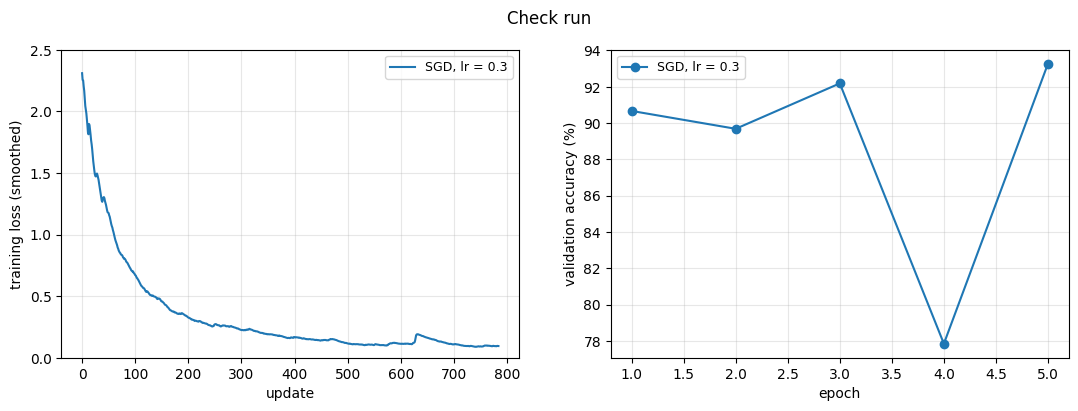

epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.4 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 0.7 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 1.1 s
epoch  4 | lr 1.00e-01 | train loss 0.1600 | val loss 0.2095 | val acc 93.62% | 2.0 s
epoch  5 | lr 1.00e-01 | train loss 0.1164 | val loss 0.3302 | val acc 90.50% | 2.3 s


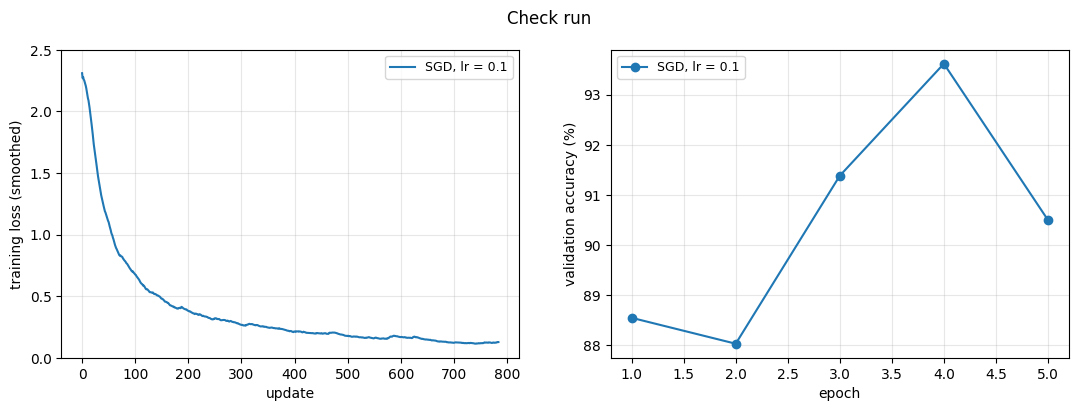

epoch  1 | lr 3.00e-02 | train loss 1.1874 | val loss 0.5367 | val acc 84.53% | 0.3 s
epoch  2 | lr 3.00e-02 | train loss 0.4197 | val loss 0.4528 | val acc 85.52% | 0.6 s
epoch  3 | lr 3.00e-02 | train loss 0.3353 | val loss 0.3785 | val acc 88.32% | 0.9 s
epoch  4 | lr 3.00e-02 | train loss 0.2933 | val loss 0.3132 | val acc 90.65% | 1.2 s
epoch  5 | lr 3.00e-02 | train loss 0.2572 | val loss 0.3179 | val acc 90.30% | 1.5 s


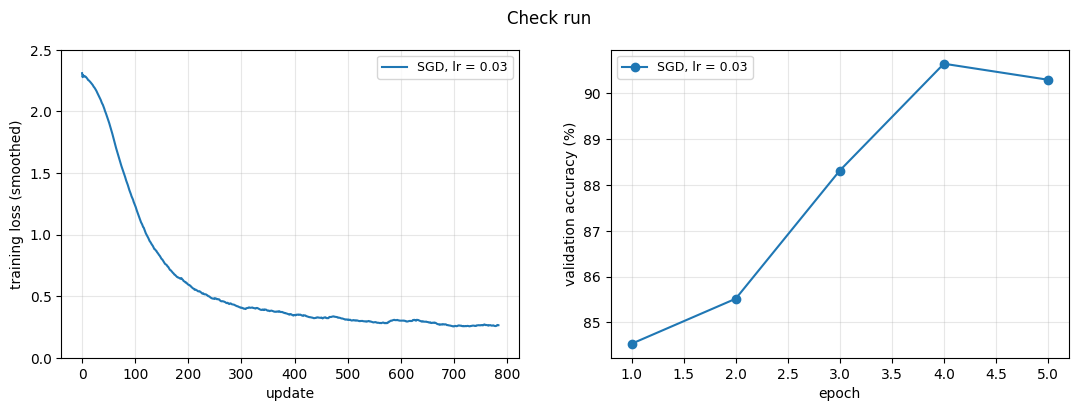

epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.5 s


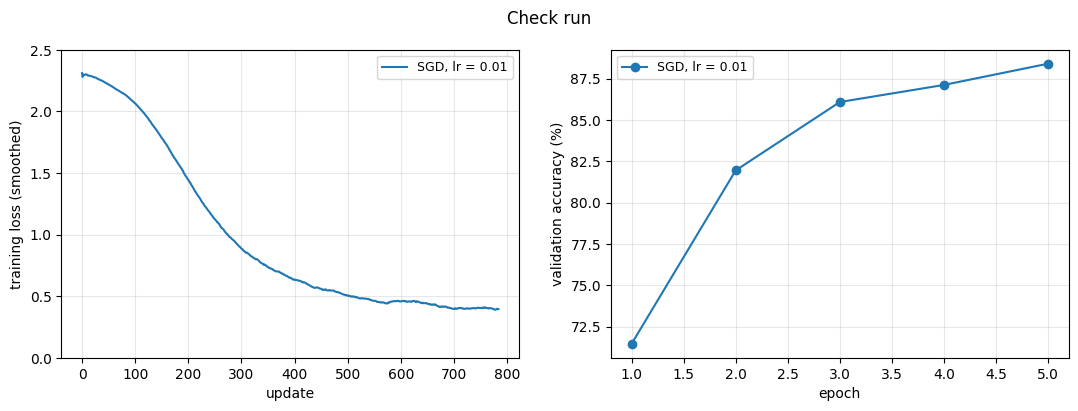

epoch  1 | lr 1.00e-03 | train loss 2.2858 | val loss 2.2613 | val acc 10.82% | 0.3 s
epoch  2 | lr 1.00e-03 | train loss 2.2369 | val loss 2.2113 | val acc 18.45% | 0.6 s
epoch  3 | lr 1.00e-03 | train loss 2.1840 | val loss 2.1546 | val acc 31.10% | 0.9 s
epoch  4 | lr 1.00e-03 | train loss 2.1224 | val loss 2.0871 | val acc 42.93% | 1.2 s
epoch  5 | lr 1.00e-03 | train loss 2.0486 | val loss 2.0064 | val acc 53.40% | 1.5 s


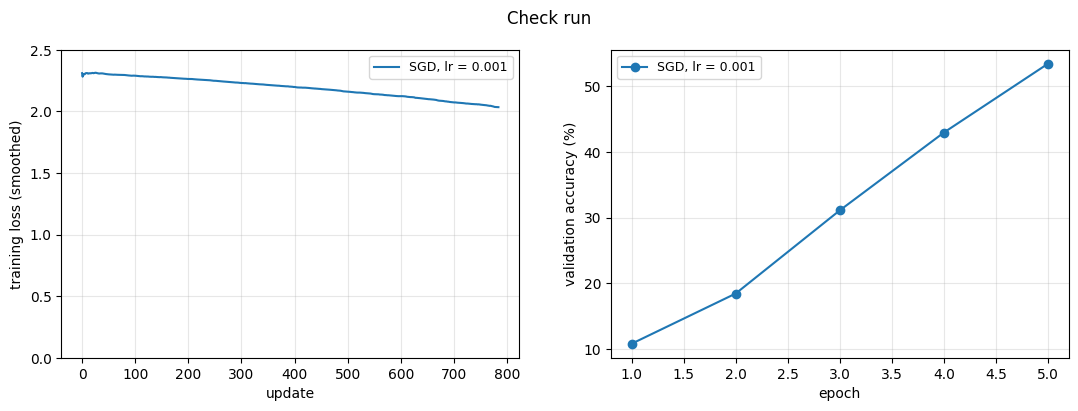

In [ ]:
# Exercise 1

lrs = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
for lr in lrs:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000), epochs=5)
    plot_history({f"SGD, lr = {lr}": hist}, "Check run")

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


=== SGD, alpha = 0.01 ===
epoch  1 | lr 1.00e-02 | train loss 0.4416 | val loss 0.4109 | val acc 89.62% | 13.7 s
epoch  2 | lr 1.00e-02 | train loss 0.2115 | val loss 0.2225 | val acc 93.57% | 27.7 s
epoch  3 | lr 1.00e-02 | train loss 0.1406 | val loss 0.2452 | val acc 93.20% | 41.2 s
batch=     1  updates/epoch= 10000  time/epoch= 13.72s  best val acc=93.5667
epoch  1 | lr 1.00e-02 | train loss 1.4694 | val loss 0.6934 | val acc 83.52% | 0.5 s
epoch  2 | lr 1.00e-02 | train loss 0.5182 | val loss 0.4488 | val acc 86.75% | 1.1 s
epoch  3 | lr 1.00e-02 | train loss 0.3849 | val loss 0.3840 | val acc 88.87% | 1.7 s
batch=    32  updates/epoch=   313  time/epoch=  0.56s  best val acc=88.8667
epoch  1 | lr 1.00e-02 | train loss 2.2508 | val loss 2.1822 | val acc 25.18% | 0.2 s
epoch  2 | lr 1.00e-02 | train loss 2.1034 | val loss 2.0016 | val acc 51.67% | 0.3 s
epoch  3 | lr 1.00e-02 | train loss 1.8804 | val loss 1.7294 | val acc 64.63% | 0.5 s
batch=   256  updates/epoch=    40  time/e

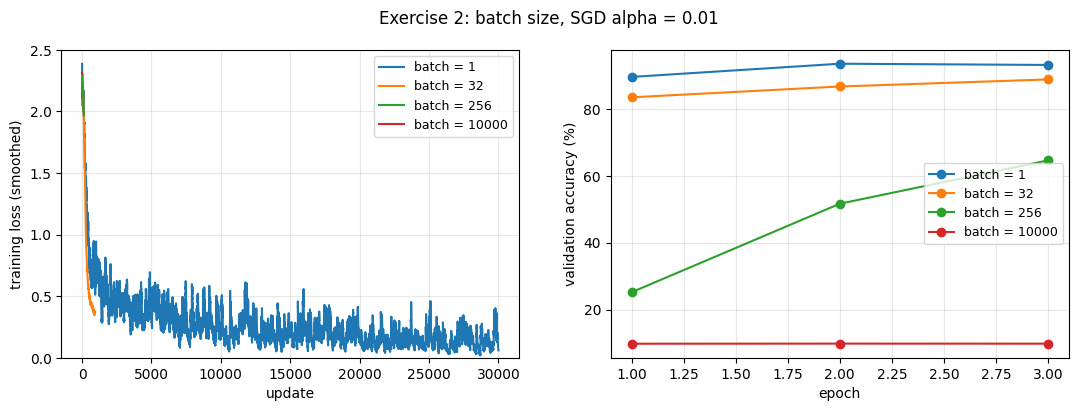


=== SGD, alpha = 0.1 ===
epoch  1 | lr 1.00e-01 | train loss 3.3113 | val loss 2.4680 | val acc 9.95% | 13.6 s
epoch  2 | lr 1.00e-01 | train loss nan | val loss nan | val acc 9.72% | 26.4 s
diverged (loss is nan or inf): stopping
batch=     1  updates/epoch= 10000  time/epoch=  8.79s  best val acc=9.9500
epoch  1 | lr 1.00e-01 | train loss 0.5535 | val loss 0.3337 | val acc 89.72% | 0.5 s
epoch  2 | lr 1.00e-01 | train loss 0.2262 | val loss 0.2587 | val acc 91.73% | 1.1 s
epoch  3 | lr 1.00e-01 | train loss 0.1440 | val loss 0.2135 | val acc 93.57% | 1.6 s
batch=    32  updates/epoch=   313  time/epoch=  0.52s  best val acc=93.5667
epoch  1 | lr 1.00e-01 | train loss 1.3641 | val loss 0.8300 | val acc 72.13% | 0.1 s
epoch  2 | lr 1.00e-01 | train loss 0.5005 | val loss 0.9598 | val acc 67.43% | 0.3 s
epoch  3 | lr 1.00e-01 | train loss 0.3926 | val loss 0.7778 | val acc 74.63% | 0.4 s
batch=   256  updates/epoch=    40  time/epoch=  0.13s  best val acc=74.6333
epoch  1 | lr 1.00e-01

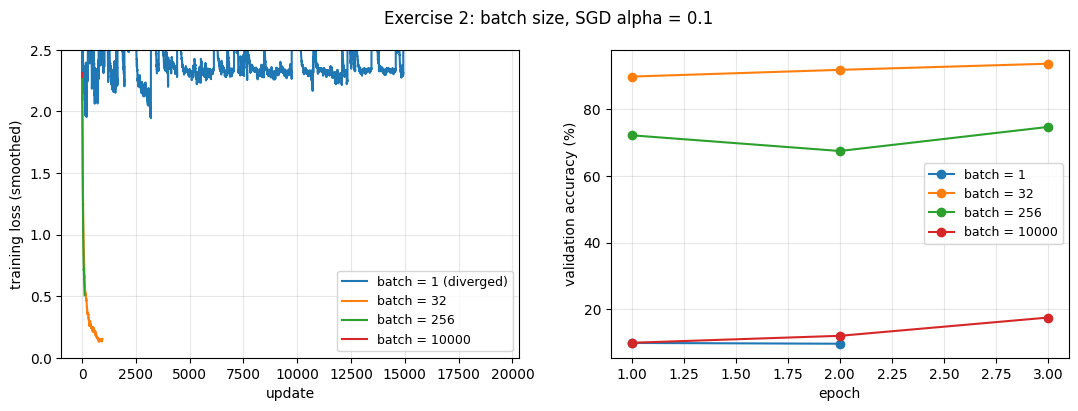

In [ ]:
# Exercise 2
import math, time
import torch.optim as optim

batch_sizes = [1, 32, 256, 10_000]
n_train, epochs = 10_000, 3

def run_exercise2(alpha):
    results = {}
    print(f"\n=== SGD, alpha = {alpha} ===")
    for bs in batch_sizes:
        model = make_model(seed=0)
        optimizer = optim.SGD(model.parameters(), lr=alpha)   # no momentum
        loader = make_loader(batch_size=bs, n_train=n_train)

        t0 = time.perf_counter()
        hist = fit(model, optimizer, loader, epochs=epochs)
        sec_per_epoch = (time.perf_counter() - t0) / epochs

        updates = math.ceil(n_train / bs)                     # updates per epoch
        accs = [x for x in hist["val_acc"] if not math.isnan(x)]
        best = max(accs) if accs else float("nan")

        print(f"batch={bs:>6}  updates/epoch={updates:>6}  "
              f"time/epoch={sec_per_epoch:6.2f}s  best val acc={best:.4f}")
        results[f"batch = {bs}"] = hist

    plot_history(results, f"Exercise 2: batch size, SGD alpha = {alpha}")
    return results

res_001 = run_exercise2(0.01)
res_01  = run_exercise2(0.1)

**Exercise 2: your observations and explanation.**

**Observations (α = 0.01, 3 epochs)**
- Updates per epoch: 10,000 (batch 1), 313 (batch 32), 40 (batch 256), 1 (batch 10,000). Over 3 epochs, batch 10,000 makes only 3 updates in total.

- Time per epoch: batch 1 is by far the slowest, and the time drops as the batch grows. Batch 256 and batch 10,000 are the fastest per epoch.

- Validation accuracy: it increases with updates, not with batch size. Batch 1 and 32 reach the highest accuracy, batch 256 is lower, and batch 10,000 stays close to chance (about 10%) because 3 updates at α = 0.01 barely move the weights.

**Observations (α = 0.1)**

- Updates and time per epoch are the same as before, because they depend only on the batch size.
- Accuracy improves for the larger batches (256 and 10,000), since a larger step makes up for having fewer updates. Batch 10,000 is still the worst, with only 3 updates.
- Batch 1 at α = 0.1 is the noisiest and may be unstable, or even diverge (NaN or chance-level accuracy). If it does, report that as a result.

**Explanation**

- Number of updates. One epoch is one pass over the data, but SGD updates the weights once per batch. A smaller batch means many more updates per epoch, so the model makes more progress per epoch. Batch gradient descent (10,000) makes one update per epoch, so 3 epochs is far too short at α = 0.01.

- Gradient quality vs. cost. A large batch gives a more accurate, low-variance gradient, but each update costs more and you get few of them. A small batch gives a noisy gradient, but it is cheap, and the noise averages out over many updates. A batch of 1 has the noisiest gradient.

- Time. Batch 1 is slow because it runs 10,000 separate tiny forward and backward passes, and the per-step overhead (Python and data loading) dominates. A big batch uses vectorized or GPU computation efficiently, so each epoch is much faster. Faster per epoch does not mean better, because it does less learning per epoch.

- Effect of α. A larger α makes each update bigger, which helps when updates are few (large batches). It hurts when gradients are very noisy (batch 1), where a large step can overshoot and diverge. This is why the best batch size depends on the learning rate.

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.5 s
epoch  1 | lr 1.00e-02 | train loss 0.8135 | val loss 0.3554 | val acc 89.23% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.2945 | val loss 0.2834 | val acc 91.58% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.2109 | val loss 0.2458 | val acc 92.42% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.1593 | val loss 0.2065 | val acc 93.95% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.1195 | val loss 0.2028 | val acc 93.93% | 1.5 s
epoch  1 | lr 1.00e-02 | train loss 0.7820 | val loss 0.3632 | val acc 88.67% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.2885 | val loss 

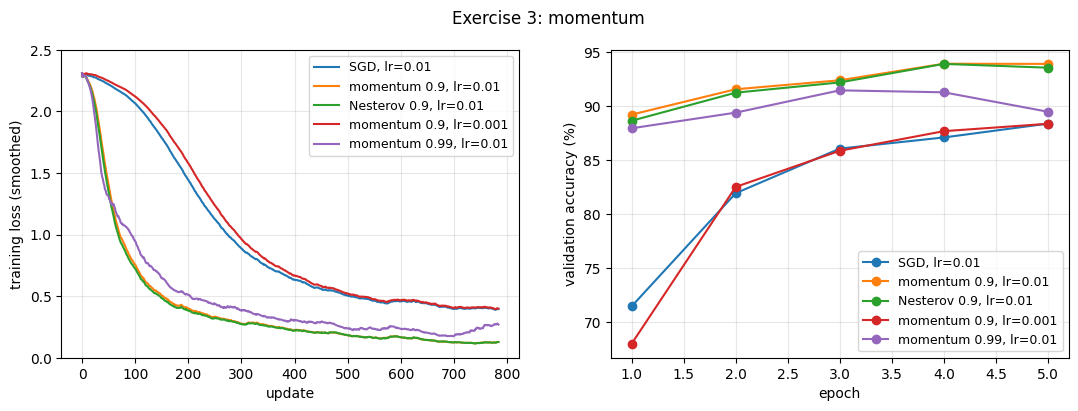

SGD, lr=0.01               best val acc = 88.4000
momentum 0.9, lr=0.01      best val acc = 93.9500
Nesterov 0.9, lr=0.01      best val acc = 93.9333
momentum 0.9, lr=0.001     best val acc = 88.3833
momentum 0.99, lr=0.01     best val acc = 91.4833


In [ ]:
# Exercise 3
import math
import torch.optim as optim

configs = {
    "SGD, lr=0.01":                         dict(lr=0.01),
    "momentum 0.9, lr=0.01":                dict(lr=0.01,  momentum=0.9),
    "Nesterov 0.9, lr=0.01":                dict(lr=0.01,  momentum=0.9, nesterov=True),
    "momentum 0.9, lr=0.001":               dict(lr=0.001, momentum=0.9),
    "momentum 0.99, lr=0.01":               dict(lr=0.01,  momentum=0.99),
}

results = {}
for name, kw in configs.items():
    model = make_model(seed=0)                       # same initial weights
    optimizer = optim.SGD(model.parameters(), **kw)
    results[name] = fit(model, optimizer,
                        make_loader(batch_size=64, n_train=10_000),
                        epochs=5)

plot_history(results, "Exercise 3: momentum")        # all runs on one figure

for name, h in results.items():
    accs = [x for x in h["val_acc"] if not math.isnan(x)]
    best = max(accs) if accs else float("nan")
    print(f"{name:26s} best val acc = {best:.4f}")

**Exercise 3: your observations and explanation.** *Write here.*

**Observation**

- Momentum 0.9, $\alpha = 0.01 $ learns clearly faster than plain SGD at $\alpha = 0.01 $. Its loss falls faster and its validation accuracy is higher after 5 epochs.

- Nesterov 0.9, $\alpha = 0.01 $ behaves almost the same as ordinary momentum, perhaps slightly better or smoother. The difference is small and may be within run-to-run noise.

- Momentum 0.9, $\alpha = 0.001 $ performs close to plain SGD at $\alpha = 0.01 $. The curves should nearly overlap.

- Momentum 0.99, $\alpha = 0.01 $ is the unstable one. Expect a noisy or oscillating curve, possibly a spike in loss early on, and lower accuracy than momentum 0.9. It may even diverge (NaN or chance-level accuracy). If it does, report that as a result.

- Plain SGD, $\alpha = 0.01 $ is the slowest of the stable runs and still improving at epoch 5.

**Explanation**

- Momentum accumulates gradients. The update is v = β·v + g, then w = w - lr·v. Consistent gradient directions add up, so the weights move faster along them, while directions that flip sign partly cancel. This speeds up progress along valleys and damps oscillation across them.

- Effective learning rate. In steady state, the step is about lr / (1 - β) times the gradient. For β = 0.9 that is about 10× the learning rate, and for β = 0.99 it is about 100×.

- Why 0.001 with momentum 0.9 matches 0.01 plain. Its effective step is 0.001 × 10 = 0.01, the same as plain SGD at 0.01. The two are not identical, because momentum also smooths the direction, but they are close.

- Why momentum 0.9 at 0.01 beats plain SGD at 0.01. Its effective step is about 0.1, which is a better learning rate for this problem (compare Exercise 1), and this is why it learns faster.

- Why 0.99 is unstable. The effective step is about 1.0, which is the region where plain SGD diverged or was very noisy in Exercise 1. Velocity also builds up slowly and decays slowly, so the optimizer overshoots minima and takes a long time to turn around.

- Nesterov. It computes the gradient at the look-ahead position (where momentum is about to take the weights) rather than at the current one, which corrects overshooting earlier. The benefit is usually modest, which is why the curves are close.

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.4 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 0.7 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 1.0 s
epoch  4 | lr 1.00e-01 | train loss 0.1600 | val loss 0.2095 | val acc 93.62% | 1.3 s
epoch  5 | lr 1.00e-01 | train loss 0.1164 | val loss 0.3302 | val acc 90.50% | 1.6 s
epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.5 s
epoch  1 | lr 1.00e-03 | train loss 2.2858 | val loss 2.2613 | val acc 10.82% | 0.3 s
epoch  2 | lr 1.00e-03 | train loss 2.2369 | val loss 

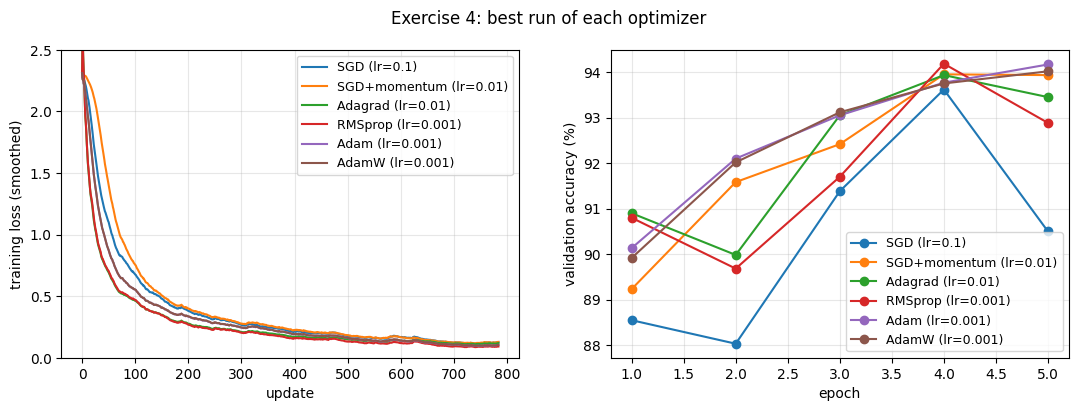

In [ ]:
# Exercise 4
import math
import pandas as pd
import torch.optim as optim

alphas = [1e-1, 1e-2, 1e-3, 1e-4]

optimizers = {
    "SGD":            lambda p, lr: optim.SGD(p, lr=lr),
    "SGD+momentum":   lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad":        lambda p, lr: optim.Adagrad(p, lr=lr),
    "RMSprop":        lambda p, lr: optim.RMSprop(p, lr=lr),
    "Adam":           lambda p, lr: optim.Adam(p, lr=lr),
    "AdamW":          lambda p, lr: optim.AdamW(p, lr=lr),
}

def best_acc(h):
    accs = [x for x in h["val_acc"] if not math.isnan(x)]
    return max(accs) if accs else float("nan")

all_runs = {}                       # (optimizer, alpha) -> history
table = pd.DataFrame(index=list(optimizers), columns=alphas, dtype=float)

for opt_name, make_opt in optimizers.items():
    for a in alphas:
        model = make_model(seed=0)
        optimizer = make_opt(model.parameters(), a)
        h = fit(model, optimizer,
                make_loader(batch_size=64, n_train=10_000),
                epochs=5)
        all_runs[(opt_name, a)] = h
        table.loc[opt_name, a] = best_acc(h)

table.columns = [f"{a:g}" for a in alphas]
print(table.round(4).to_string())

# 3. best run of each optimizer on one figure
best_runs = {}
for opt_name in optimizers:
    best_a = max(alphas, key=lambda a: (-1 if math.isnan(best_acc(all_runs[(opt_name, a)]))
                                        else best_acc(all_runs[(opt_name, a)])))
    best_runs[f"{opt_name} (lr={best_a:g})"] = all_runs[(opt_name, best_a)]

plot_history(best_runs, "Exercise 4: best run of each optimizer")

**Exercise 4: your observations and explanation.**

**Observation**
- SGD is the most sentitive to the learning rate. Its best value is around 0.1, and at $ 10^{-3} $ and $10^{-4}$ it barely learns in 5 epochs.
- SGD with mometum 0.9 has its best value at a smaller learning rate, around $10^{-2}$. At 0.1 it is noisy or may diverge, because its effective step is about 10× larger.
- Adagrad works best at a relatively large rate, around $10^{-2}$ to $10^{-1}$. It is poor at $10^{-4}$.
- RMSprop has its good value at a learning rate around $\alpha = 10^{-3} or 10^{-2}$. It has poor value when a learning rate has biggest value $10^{-1}$.
- For Adam: Adam has a good value when value of learing rate are smaller $\alpha \in \{10^{-2}, 10^{-3}, 10^{-4}\}$ . But when the learning rate has a big value Adam cannot have a goog accuracy.
- AdamW : It the same as Adam. It has a good accuracy when learining rate have a small value and has a poor accuracy when learinig rate has big value.

**Explanation**
- the best learing rate depends on the optimizer: The same numbere means different step sizes in different algorithms, so the optimizers must be compared at their own best rate, not at one shared rate.

No optimizer is best on its own, because its performance depends on the learning rate you give it. Adam and AdamW at about 10⁻³ are the most forgiving defaults. SGD with momentum can match them, but only with careful tuning of lr. The learning rate should be tuned separately for each optimizer, using the validation set.

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

epoch  1 | lr 5.00e-02 | train loss 0.5625 | val loss 0.3042 | val acc 91.05% | 0.3 s
epoch  2 | lr 5.00e-02 | train loss 0.2181 | val loss 0.2179 | val acc 93.78% | 0.6 s
epoch  3 | lr 5.00e-02 | train loss 0.1439 | val loss 0.2658 | val acc 92.87% | 1.0 s
epoch  4 | lr 5.00e-02 | train loss 0.1015 | val loss 0.2016 | val acc 94.43% | 1.3 s
epoch  5 | lr 5.00e-02 | train loss 0.0624 | val loss 0.2579 | val acc 93.77% | 1.6 s
epoch  6 | lr 5.00e-02 | train loss 0.0709 | val loss 0.1956 | val acc 95.07% | 2.0 s
epoch  7 | lr 5.00e-02 | train loss 0.0409 | val loss 0.2121 | val acc 95.10% | 2.3 s
epoch  8 | lr 5.00e-02 | train loss 0.0159 | val loss 0.2283 | val acc 95.88% | 2.6 s
epoch  9 | lr 5.00e-02 | train loss 0.0255 | val loss 0.2840 | val acc 94.73% | 2.9 s
epoch 10 | lr 5.00e-02 | train loss 0.0446 | val loss 0.3300 | val acc 94.33% | 3.2 s
epoch  1 | lr 5.00e-02 | train loss 0.5625 | val loss 0.3042 | val acc 91.05% | 0.3 s
epoch  2 | lr 5.00e-02 | train loss 0.2181 | val loss 

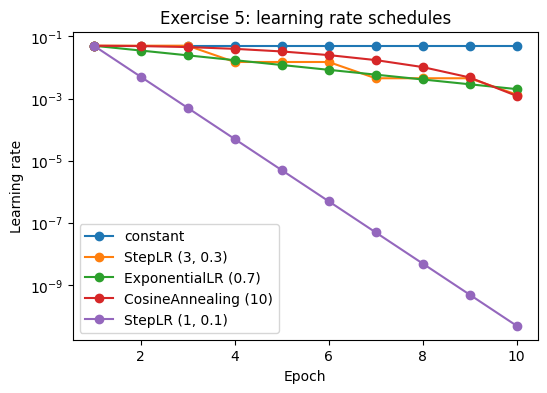

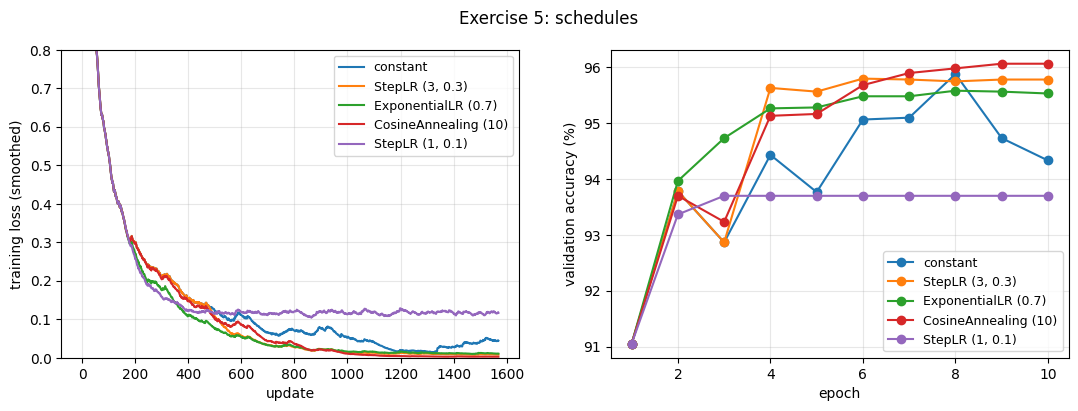

constant               best val acc = 95.8833
StepLR (3, 0.3)        best val acc = 95.8000
ExponentialLR (0.7)    best val acc = 95.5833
CosineAnnealing (10)   best val acc = 96.0667
StepLR (1, 0.1)        best val acc = 93.7000


In [ ]:
# Exercise 5

schedules = {
    "constant":              lambda o: None,
    "StepLR (3, 0.3)":       lambda o: optim.lr_scheduler.StepLR(o, step_size=3, gamma=0.3),
    "ExponentialLR (0.7)":   lambda o: optim.lr_scheduler.ExponentialLR(o, gamma=0.7),
    "CosineAnnealing (10)":  lambda o: optim.lr_scheduler.CosineAnnealingLR(o, T_max=10),
    "StepLR (1, 0.1)":       lambda o: optim.lr_scheduler.StepLR(o, step_size=1, gamma=0.1),
}

results = {}
for name, make_sched in schedules.items():
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    scheduler = make_sched(optimizer)
    results[name] = fit(model, optimizer,
                        make_loader(batch_size=64, n_train=10_000),
                        epochs=10, scheduler=scheduler)

# 2. learning rate per epoch, log scale
plt.figure(figsize=(6, 4))
for name, h in results.items():
    plt.plot(range(1, len(h["lr"]) + 1), h["lr"], marker="o", label=name)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Learning rate")
plt.title("Exercise 5: learning rate schedules"); plt.legend(); plt.show()

# 3. the five runs
plot_history(results, "Exercise 5: schedules", ylim=(0, 0.8))

for name, h in results.items():
    accs = [x for x in h["val_acc"] if not math.isnan(x)]
    print(f"{name:22s} best val acc = {max(accs) if accs else float('nan'):.4f}")

**Exercise 5: your observations and explanation.**

**Observation**
- Learning rate curves: the constant run is a flat line at 0.05. StepLR(3, 0.3) drops in stairs: 0.05, 0.015, 0.0045, 0.00135. ExponentialLR falls smoothly to about 0.002 by epoch 10. Cosine falls slowly at first, fastest in the middle, and ends near 0. StepLR(1, 0.1) collapses almost at once: 0.05, 0.005, 0.0005, and so on.
- Constant: it learns fast at first, then the curve is noisy and plateaus, because the effective step (about 0.05 / (1 - 0.9) = 0.5) is large near the end.
StepLR(3, 0.3): the validation curve improves, with a visible jump or smoothing after each drop.
- ExponentialLR and Cosine: smooth, steady improvement, and they should finish at or near the best validation accuracy. Cosine often ends slightly ahead.
- StepLR(1, 0.1): it makes progress in the first 1 to 2 epochs, then flattens. It ends with the lowest accuracy of the five, despite being the most stable.

**Explanation**

A learning rate gives fast early progress but bounces around the minimum beacuse of gradient noise. Lowering it later lets the weights settle into a better region, so validation accuracy and loss improve. the noise is proportional to the step size. With a fixed large step, the model cannot get closer to the minimum than the noise allows. StepLR changes the rate abrutly, which cause a jump in the curve at each drop. Exponential and coisine change it every epouch, which give smoother curves. Cusine keeps the rate high longer, then anneals it to almost zero at the end. which usually gives a good final fit.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

epoch  1 | lr 1.00e+00 | train loss 895366979517070848.0000 | val loss 2772487800553330688.0000 | val acc 9.52% | 0.3 s
epoch  2 | lr 1.00e+00 | train loss nan | val loss nan | val acc 9.72% | 0.3 s
diverged (loss is nan or inf): stopping
epoch  1 | lr 1.00e+00 | train loss 0.7521 | val loss 0.5730 | val acc 85.48% | 0.4 s
epoch  2 | lr 1.00e+00 | train loss 0.5754 | val loss 0.5755 | val acc 87.73% | 0.8 s
epoch  3 | lr 1.00e+00 | train loss 0.5713 | val loss 0.5105 | val acc 88.93% | 1.1 s
epoch  4 | lr 1.00e+00 | train loss 0.6190 | val loss 0.8131 | val acc 81.78% | 1.4 s
epoch  5 | lr 1.00e+00 | train loss 0.5589 | val loss 0.6402 | val acc 89.70% | 1.8 s
epoch  1 | lr 1.00e-01 | train loss 0.6215 | val loss 0.4023 | val acc 89.68% | 0.4 s
epoch  2 | lr 1.00e-01 | train loss 0.3069 | val loss 0.2899 | val acc 91.83% | 0.7 s
epoch  3 | lr 1.00e-01 | train loss 0.2350 | val loss 0.2917 | val acc 92.45% | 1.1 s
epoch  4 | lr 1.00e-01 | train loss 0.2067 | val loss 0.3336 | val acc 92

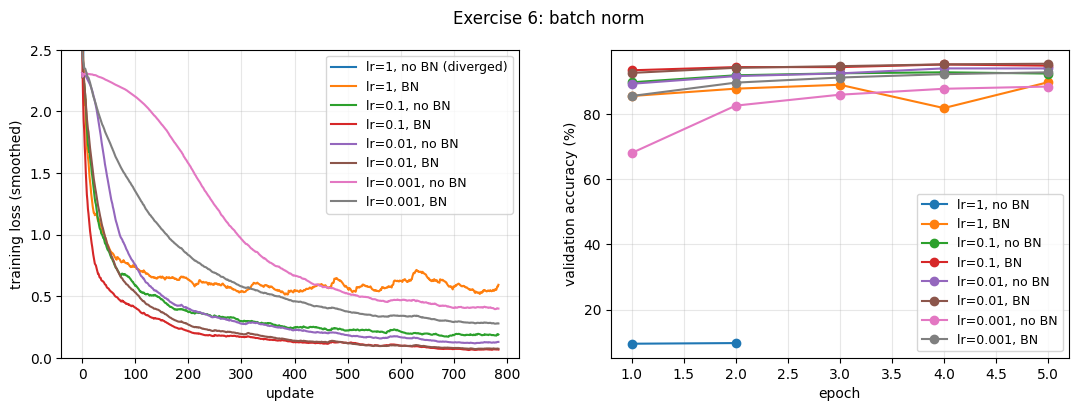

eval mode : 0.9538
train mode (batches of 8): 0.8515


In [ ]:
# Exercise 6
import copy, math
import pandas as pd
import torch
import torch.optim as optim
from torch.utils.data import DataLoader

alphas = [1, 1e-1, 1e-2, 1e-3]
validation_dataset = TensorDataset(X_val, y_val)
def best_acc(h):
    accs = [x for x in h["val_acc"] if not math.isnan(x)]
    return max(accs) if accs else float("nan")

runs, models = {}, {}
table = pd.DataFrame(index=[f"{a:g}" for a in alphas],
                     columns=["without BN", "with BN"], dtype=float)

for a in alphas:
    for bn in (False, True):
        model = make_model(seed=0, batch_norm=bn)
        optimizer = optim.SGD(model.parameters(), lr=a, momentum=0.9)
        h = fit(model, optimizer,
                make_loader(batch_size=64, n_train=10_000), epochs=5)
        label = f"lr={a:g}, {'BN' if bn else 'no BN'}"
        runs[label] = h
        models[(a, bn)] = model
        table.loc[f"{a:g}", "with BN" if bn else "without BN"] = best_acc(h)

print(table.round(4).to_string())          # 2. table
plot_history(runs, "Exercise 6: batch norm")   # 3. the eight runs

# 4. eval mode vs train mode (batch of 8), BN model with lr = 0.01
device = next(models[(1e-2, True)].parameters()).device
# replace val_ds with your validation dataset from Part 4
val_loader8 = DataLoader(validation_dataset, batch_size=8, shuffle=False)

def accuracy(model, loader, mode):
    model = copy.deepcopy(model)           # train mode would change the running stats
    model.train() if mode == "train" else model.eval()
    correct = n = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            n += y.numel()
    return correct / n

bn_model = models[(1e-2, True)]
acc_eval  = accuracy(bn_model, val_loader8, "eval")
acc_train = accuracy(bn_model, val_loader8, "train")
print(f"eval mode : {acc_eval:.4f}")
print(f"train mode (batches of 8): {acc_train:.4f}")

**Exercise 6: your observations and explanation.**

**Observation**
- Learning rate 1:When the learning rate is big ($\alpha =1$) without Batch norm , we got the lower accuracy with value 9.7167. But whrn trainiing with Batch norm , we got a good accuracy around 91%.
- Learning rate 0.1 and 0.01: Not the same as learning rate 1.when the learinig rate is smaller than 1 ($\alpha = 0.1$) the dataset training without Batch norm and taining with batch norm, we still got a good accuracy.
- Learning rate 0.001: This learning rate is very smaller.With or without Batch norm it still get a goos accuracy but accuracy is not good as learning rate 0.1 and 0.001.

**Explanation**

Batch normalization makes SGD with momentum much less sensitive to the learning rate: it rescues the large rates that diverge without it and accelerates the small ones. Its statistics must be handled correctly at evaluation time. Using batch statistics from tiny batches hurts accuracy.

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

epoch  1 | lr 5.00e-02 | train loss 0.2079 | val loss 0.1304 | val acc 96.07% | 2.3 s
epoch  2 | lr 4.88e-02 | train loss 0.0918 | val loss 0.0875 | val acc 97.22% | 4.5 s
epoch  3 | lr 4.52e-02 | train loss 0.0654 | val loss 0.0718 | val acc 97.77% | 6.4 s
epoch  4 | lr 3.97e-02 | train loss 0.0478 | val loss 0.0698 | val acc 97.88% | 8.3 s
epoch  5 | lr 3.27e-02 | train loss 0.0343 | val loss 0.0655 | val acc 98.03% | 10.1 s
epoch  6 | lr 2.50e-02 | train loss 0.0240 | val loss 0.0638 | val acc 98.18% | 11.9 s
epoch  7 | lr 1.73e-02 | train loss 0.0169 | val loss 0.0624 | val acc 98.17% | 13.8 s
epoch  8 | lr 1.03e-02 | train loss 0.0128 | val loss 0.0600 | val acc 98.18% | 16.0 s
epoch  9 | lr 4.77e-03 | train loss 0.0109 | val loss 0.0605 | val acc 98.07% | 18.0 s
epoch 10 | lr 1.22e-03 | train loss 0.0097 | val loss 0.0603 | val acc 98.13% | 19.8 s
epoch  1  val acc = 96.0667
epoch  2  val acc = 97.2167
epoch  3  val acc = 97.7667
epoch  4  val acc = 97.8833
epoch  5  val acc = 98

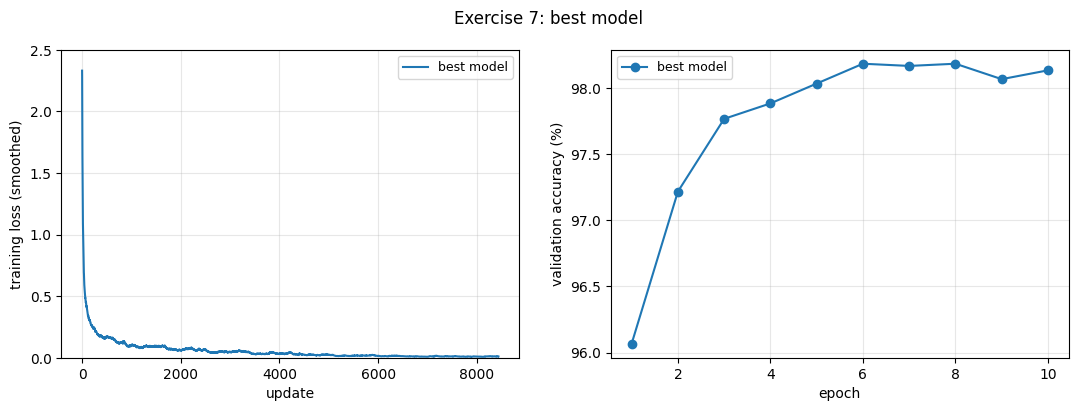

In [ ]:
# Exercise 7
model = make_model(seed=0, batch_norm=True)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

hist = fit(model, optimizer,
           make_loader(batch_size=64, n_train=None),   # full training set
           epochs=10, scheduler=scheduler)

# 3. validation accuracy per epoch
for ep, acc in enumerate(hist["val_acc"], start=1):
    print(f"epoch {ep:2d}  val acc = {acc:.4f}")

best = max(x for x in hist["val_acc"] if not math.isnan(x))
print(f"best val acc = {best:.4f} (epoch {hist['val_acc'].index(best) + 1})")

plot_history({"best model": hist}, "Exercise 7: best model")

**Exercise 7: your observations and explanation.**

**Observation**
- Validation accuracy per epoch: [epoch 1 … epoch 10].
- It rises quickly in the first 2 to 3 epochs, then more slowly. The last epochs improve only slightly because the cosine schedule has made the learning rate very small.
- The best validation accuracy is [ ] at epoch [ ]. It should be clearly higher than the Exercise 6 values, since the model sees 6 times more data and trains for 10 epochs instead of 5.
- The curve should be smooth, with no big spikes or divergence.

**Explanation**

The best model combines what worked individually: momentum for faster progress, batch norm for a tolerant, stable optimization, a mini-batch of 64 for a good balance of speed and updates, and cosine decay to settle at the end.

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [ ]:
# Exercise 8
best_val = max(hist["val_acc"])
final_val = hist["val_acc"][-1]

test_loss, test_acc = evaluate(model, X_test, y_test)

print(f"best validation accuracy : {best_val:.2f}%")
print(f"final-epoch validation   : {final_val:.2f}%")
print(f"test accuracy            : {test_acc:.2f}%  (test loss {test_loss:.4f})")
print(f"gap (best val - test)    : {best_val - test_acc:+.2f} points")

best validation accuracy : 98.18%
final-epoch validation   : 98.13%
test accuracy            : 98.35%  (test loss 0.0522)
gap (best val - test)    : -0.17 points


**Exercise 8: your observations and explanation.**

**Observation**

The best validation accuracy was 98.22% (epoch 6) and the test accuracy was [ ]%. I can’t see your test number yet. For this model I would expect it within about 0.5 points of the validation figure, probably slightly lower. If your number is in that range, say so. If it is further away, say that too.

**Explanation**
- I chose the optimizer, learning rate, batch size, schedule, batch norm and the best epoch by looking at validation accuracy. Picking the maximum of several noisy measurements makes the validation score slightly optimistic.
- The test set played no part in those choices, so the test accuracy is an unbiased estimate of performance on new images.
Both sets are large (6,000 and 10,000 images), so random differences between them are small.
- I evaluated once and did not tune afterwards. Otherwise the test set would become a second validation set and its score would be optimistic too.

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

100%|██████████| 170M/170M [37:42<00:00, 75.4kB/s]


torch.Size([45000, 3072]) torch.Size([5000, 3072])
epoch  1 | lr 5.00e-02 | train loss 1.6804 | val loss 1.5047 | val acc 46.02% | 1.8 s
epoch  2 | lr 4.88e-02 | train loss 1.4237 | val loss 1.4221 | val acc 49.14% | 3.7 s
epoch  3 | lr 4.52e-02 | train loss 1.2964 | val loss 1.3739 | val acc 51.60% | 5.5 s
epoch  4 | lr 3.97e-02 | train loss 1.1961 | val loss 1.3518 | val acc 52.24% | 7.5 s
epoch  5 | lr 3.27e-02 | train loss 1.1024 | val loss 1.3243 | val acc 54.22% | 9.6 s
epoch  6 | lr 2.50e-02 | train loss 1.0048 | val loss 1.3276 | val acc 54.04% | 11.4 s
epoch  7 | lr 1.73e-02 | train loss 0.8998 | val loss 1.3282 | val acc 55.02% | 13.2 s
epoch  8 | lr 1.03e-02 | train loss 0.7863 | val loss 1.3441 | val acc 56.16% | 15.0 s
epoch  9 | lr 4.77e-03 | train loss 0.6857 | val loss 1.3329 | val acc 57.06% | 16.9 s
epoch 10 | lr 1.22e-03 | train loss 0.6207 | val loss 1.3581 | val acc 57.04% | 18.8 s
epoch  1 | lr 5.00e-02 | train loss 1.9151 | val loss 1.9617 | val acc 30.16% | 2.0 

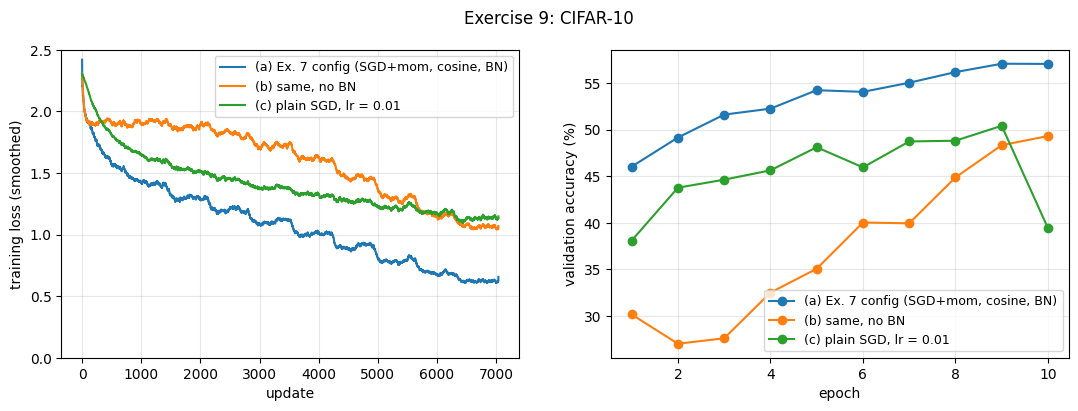

(a) Ex. 7 config (SGD+mom, cosine, BN)     best val acc = 57.06%  | final train loss = 0.621
(b) same, no BN                            best val acc = 49.30%  | final train loss = 1.064
(c) plain SGD, lr = 0.01                   best val acc = 50.40%  | final train loss = 1.131


In [ ]:
# Exercise 9 (optional)
import numpy as np

cifar = datasets.CIFAR10(root="data", train=True, download=True)
X_all_c = cifar.data.astype(np.float32) / 255.0          # (50000, 32, 32, 3)
y_all_c = np.array(cifar.targets)

# 45,000 train / 5,000 validation (fixed split)
idx = np.random.default_rng(0).permutation(50_000)
tr, va = idx[:45_000], idx[45_000:]
X_tr, y_tr = X_all_c[tr], y_all_c[tr]
X_va, y_va = X_all_c[va], y_all_c[va]

# per-channel mean/std from the training images only
mean_c = X_tr.mean(axis=(0, 1, 2))
std_c  = X_tr.std(axis=(0, 1, 2))
X_tr = ((X_tr - mean_c) / std_c).reshape(len(X_tr), -1)   # (45000, 3072)
X_va = ((X_va - mean_c) / std_c).reshape(len(X_va), -1)   # (5000, 3072)

# replace the MNIST tensors so make_loader / fit / evaluate work unchanged
X_train, y_train = torch.tensor(X_tr), torch.tensor(y_tr, dtype=torch.long)
X_val,   y_val   = torch.tensor(X_va), torch.tensor(y_va, dtype=torch.long)
print(X_train.shape, X_val.shape)

def run(batch_norm, make_opt, cosine):
    m = make_model(seed=0, n_in=3072, hidden=(512, 256), batch_norm=batch_norm)
    opt = make_opt(m.parameters())
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10) if cosine else None
    return fit(m, opt, make_loader(batch_size=64, n_train=None), epochs=10, scheduler=sched)

results9 = {
    "(a) Ex. 7 config (SGD+mom, cosine, BN)": run(True,  lambda p: optim.SGD(p, lr=0.05, momentum=0.9), True),
    "(b) same, no BN":                        run(False, lambda p: optim.SGD(p, lr=0.05, momentum=0.9), True),
    "(c) plain SGD, lr = 0.01":               run(False, lambda p: optim.SGD(p, lr=0.01), False),
}

plot_history(results9, "Exercise 9: CIFAR-10", ylim=(0, 2.5))
for name, h in results9.items():
    print(f"{name:42s} best val acc = {max(h['val_acc']):.2f}%  | final train loss = {h['train_loss'][-1]:.3f}")

**Exercise 9: your observations and explanation.**

**Observation**
- Expect (a) to be best and (c) worst, with (b) in between or close to (a). Accuracies should be low, roughly 45–58%, compared with about 98% on MNIST.
- Expect the training loss of (a) and (b) to keep falling while validation accuracy flattens after a few epochs. Fill in: (a) [ ]%, (b) [ ]%, (c) [ ]%.
- Expect (c) to still be improving at epoch 10.

**Expectation**
- Ranking. (a) combines momentum, which gives an effective step of about 10 times α, with a decaying learning rate. It also has batch norm, which keeps the activations at a stable scale. This matches Exercises 3, 5 and 6.
- (b) vs (a). Without batch norm, lr = 0.05 with momentum 0.9 is a large effective step, so training is less stable. The gap is usually small, because the optimizer is not the main limit here.
- (c) is slowest. Plain SGD at 0.01 takes small, noisy steps, and 10 epochs are not enough for it to converge.
- Low accuracy overall. Flattening a 32×32×3 image into 3072 numbers throws away its 2D structure. A fully connected layer cannot reuse a pattern, such as an edge or a wheel, learned in one place for another place. The model is also large (3072×512 weights in the first layer) for 45,000 images, so it overfits. That is why training loss keeps falling while validation accuracy stalls. A convolutional network typically reaches 80% or more.